In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"


FILE_PATH = Path("FMCG_Real_World_Data_Analyst_Practice.xlsx")


sales_raw = pd.read_excel(FILE_PATH, sheet_name="Raw_Sales")
products_raw = pd.read_excel(FILE_PATH, sheet_name="Product_Master")
customers_raw = pd.read_excel(FILE_PATH, sheet_name="Customer_Master")

print("Sales:", sales_raw.shape)
print("Products:", products_raw.shape)
print("Customers:", customers_raw.shape)


Sales: (614, 19)
Products: (23, 6)
Customers: (61, 7)


In [3]:
# Work on copies so the original imported data stays unchanged.
sales = sales_raw.copy()
products = products_raw.copy()
customers = customers_raw.copy()

# Remove only fully identical sales rows.
sales = sales.drop_duplicates().copy()
print("Exact duplicate sales rows removed:", len(sales_raw) - len(sales))

def clean_text(series):
    return series.astype("string").str.strip().replace({"": pd.NA})

def title_case(series):
    return clean_text(series).str.title()

# Standardize ID columns.
for df, cols in [
    (sales, ["Order_ID", "Customer_ID", "Product_ID"]),
    (products, ["Product_ID"]),
    (customers, ["Customer_ID"])
]:
    for col in cols:
        df[col] = clean_text(df[col]).str.upper()

# Standardize region names.
region_map = {
    "N": "North", "NRTH": "North", "NORTH": "North",
    "S": "South", "SOUTH": "South",
    "E": "East", "EAST": "East",
    "W": "West", "WEST": "West", "WESTT": "West"
}

def standardize_region(series):
    x = clean_text(series).str.upper()
    return x.map(region_map).fillna(x.str.title())

sales["Region"] = standardize_region(sales["Region"])
customers["Region"] = standardize_region(customers["Region"])

# Standardize city names and known spelling variants.
city_map = {
    "DELHI": "Delhi", "MUMBAI": "Mumbai", "KOLKATA": "Kolkata",
    "CHENNAI": "Chennai", "BENGALURU": "Bengaluru",
    "HYDERABAD": "Hyderabad", "HYDRABAD": "Hyderabad",
    "AHMEDABAD": "Ahmedabad", "BHUBANESWAR": "Bhubaneswar",
    "PATNA": "Patna", "LUCKNOW": "Lucknow", "PUNE": "Pune",
    "CHANDIGARH": "Chandigarh"
}

for df in [sales, customers]:
    city = clean_text(df["City"]).str.upper()
    df["City"] = city.map(city_map).fillna(city.str.title())

# Standardize product descriptions.
for col in ["Category", "Brand", "Product_Name"]:
    sales[col] = title_case(sales[col])
    products[col] = title_case(products[col])

# Standardize sales channel and other categories.
sales["Sales_Channel"] = title_case(sales["Sales_Channel"]).replace({
    "Distributer": "Distributor"
})
sales["Payment_Method"] = title_case(sales["Payment_Method"]).replace({
    "Credit Card": "Card"
})
sales["Order_Status"] = clean_text(sales["Order_Status"]).str.lower().str.title()
sales["Order_Status"] = sales["Order_Status"].replace({
    "Canceled": "Cancelled"
})
customers["Customer_Type"] = title_case(customers["Customer_Type"]).replace({
    "Super Market": "Supermarket"
})
customers["Loyalty_Tier"] = title_case(customers["Loyalty_Tier"])

print("Text standardization completed.")


Exact duplicate sales rows removed: 8
Text standardization completed.


In [4]:
# Convert date columns.
sales["Order_Date"] = pd.to_datetime(sales["Order_Date"], errors="coerce", format="mixed")
customers["Join_Date"] = pd.to_datetime(customers["Join_Date"], errors="coerce", format="mixed")

# Convert numeric columns and remove currency symbols/commas.
def to_number(series):
    cleaned = (series.astype("string")
               .str.replace(r"[$,]", "", regex=True)
               .str.replace(r"\s", "", regex=True))
    return pd.to_numeric(cleaned, errors="coerce")

for col in ["Quantity", "Unit_Price", "Sales_Amount", "Cost_Amount", "Profit"]:
    sales[col] = to_number(sales[col])

for col in ["Unit_Price", "Unit_Cost"]:
    products[col] = to_number(products[col])

# Convert discount values: 10, 10%, and 0.10 are treated as 10%.
discount_text = clean_text(sales["Discount_Pct"])
has_percent = discount_text.str.contains("%", na=False).fillna(False)
discount_num = pd.to_numeric(
    discount_text.str.replace("%", "", regex=False), errors="coerce"
).astype("float64")

has_percent = has_percent.to_numpy(dtype=bool)
discount_num = discount_num.to_numpy(dtype=float)

sales["Discount_Pct"] = np.where(
    has_percent,
    discount_num / 100,
    np.where(discount_num > 1, discount_num / 100, discount_num)
)

sales["Discount_Invalid_Flag"] = (
    pd.isna(sales["Discount_Pct"]) |
    (sales["Discount_Pct"] < 0) |
    (sales["Discount_Pct"] > 1)
)
sales.loc[sales["Discount_Invalid_Flag"], "Discount_Pct"] = np.nan

# Convert return values to 0/1.
returned_map = {
    "0": 0, "0.0": 0, "NO": 0, "N": 0, "FALSE": 0,
    "1": 1, "1.0": 1, "YES": 1, "Y": 1, "TRUE": 1
}
sales["Returned_Binary"] = clean_text(sales["Returned"]).str.upper().map(returned_map)

# Basic quality flags.
sales["Quantity_Invalid_Flag"] = sales["Quantity"].isna() | sales["Quantity"].le(0)
sales["Unit_Price_Invalid_Flag"] = sales["Unit_Price"].isna() | sales["Unit_Price"].le(0)
sales["Order_Date_Invalid_Flag"] = sales["Order_Date"].isna()
products["Unit_Cost_Invalid_Flag"] = products["Unit_Cost"].isna() | products["Unit_Cost"].le(0)

print("Invalid quantities:", sales["Quantity_Invalid_Flag"].sum())
print("Invalid discounts:", sales["Discount_Invalid_Flag"].sum())
print("Unrecognized return values:", sales["Returned_Binary"].isna().sum())
print("Invalid order dates:", sales["Order_Date_Invalid_Flag"].sum())


Invalid quantities: 48
Invalid discounts: 39
Unrecognized return values: 4
Invalid order dates: 5


In [5]:
# Check master-table keys.
print("Duplicate Product_ID values:", products["Product_ID"].duplicated().sum())
print("Duplicate Customer_ID values:", customers["Customer_ID"].duplicated().sum())

# Keep one row per master ID before joining, to prevent accidental row multiplication.
products = products.drop_duplicates(subset="Product_ID", keep="first").copy()
customers = customers.drop_duplicates(subset="Customer_ID", keep="first").copy()

# Join product and customer details to each sales row.
fact = sales.merge(
    products[["Product_ID", "Product_Name", "Category", "Brand", "Unit_Cost"]],
    on="Product_ID", how="left", suffixes=("", "_Master")
)
fact = fact.merge(
    customers[["Customer_ID", "Customer_Type", "Loyalty_Tier", "Join_Date"]],
    on="Customer_ID", how="left"
)

# Use product-master descriptions where available.
for col in ["Product_Name", "Category", "Brand"]:
    master_col = col + "_Master"
    if master_col in fact.columns:
        fact[col] = fact[master_col].combine_first(fact[col])

# Calculate expected sales and cost amounts.
fact["Sales_Amount_Calc"] = (
    fact["Quantity"] * fact["Unit_Price"] * (1 - fact["Discount_Pct"])
)
fact["Cost_Amount_Calc"] = (
    fact["Quantity"] * fact["Unit_Cost"].where(fact["Unit_Cost"].gt(0))
)

# Flag major quantity/cost mismatches (more than 20%).
fact["Quantity_Amount_Mismatch_Flag"] = (
    fact["Quantity"].gt(0) &
    fact["Cost_Amount"].gt(0) &
    fact["Cost_Amount_Calc"].notna() &
    (
        (fact["Cost_Amount_Calc"] - fact["Cost_Amount"]).abs()
        / fact["Cost_Amount"].abs()
    ).gt(0.20)
)

# Prefer calculated amounts where reliable; use source values as fallback.
fact["Sales_Amount_Final"] = fact["Sales_Amount_Calc"].fillna(fact["Sales_Amount"])

fact["Cost_Amount_Final"] = (
    fact["Cost_Amount_Calc"]
    .where(~fact["Quantity_Amount_Mismatch_Flag"])
    .fillna(fact["Cost_Amount"])
)

# Calculate profit; use source profit only where calculated profit is unavailable.
fact["Profit_Final"] = fact["Sales_Amount_Final"] - fact["Cost_Amount_Final"]
fact["Profit_Final"] = fact["Profit_Final"].fillna(fact["Profit"])

# Define returned, cancelled and delivered orders.
fact["Is_Returned"] = (
    fact["Returned_Binary"].eq(1) |
    fact["Order_Status"].eq("Returned")
)
fact["Is_Cancelled"] = fact["Order_Status"].eq("Cancelled")
fact["Is_Delivered"] = fact["Order_Status"].eq("Delivered")

# Recognize delivered, non-returned, positive-quantity transactions with valid dates.
fact["Is_Recognized"] = (
    fact["Is_Delivered"] &
    ~fact["Is_Returned"] &
    fact["Quantity"].gt(0) &
    fact["Order_Date"].notna()
)

fact["Recognized_Revenue"] = fact["Sales_Amount_Final"].where(fact["Is_Recognized"], 0)
fact["Recognized_Cost"] = fact["Cost_Amount_Final"].where(fact["Is_Recognized"], 0)
fact["Recognized_Profit"] = fact["Profit_Final"].where(fact["Is_Recognized"], 0)

# Exclude mismatched quantities from unit totals until the source is verified.
fact["Recognized_Quantity"] = fact["Quantity"].where(
    fact["Is_Recognized"] & ~fact["Quantity_Amount_Mismatch_Flag"], 0
)

print("Fact table shape:", fact.shape)
print("Recognized sales rows:", fact["Is_Recognized"].sum())
print("Quantity/cost mismatch rows:", fact["Quantity_Amount_Mismatch_Flag"].sum())

recognized = fact.loc[fact["Is_Recognized"]].copy()
display(recognized.head())


Duplicate Product_ID values: 0
Duplicate Customer_ID values: 0
Fact table shape: (606, 45)
Recognized sales rows: 450
Quantity/cost mismatch rows: 15


,Order_ID,Order_Date,Customer_ID,Region,City,Product_ID,Product_Name,Category,Brand,Quantity,...,Cost_Amount_Final,Profit_Final,Is_Returned,Is_Cancelled,Is_Delivered,Is_Recognized,Recognized_Revenue,Recognized_Cost,Recognized_Profit,Recognized_Quantity
0,ORD10278,2024-04-19,C018,East,Kolkata,P009,Masala Instant Noodles,Noodles,Quickbowl,200,...,60.0,21.0,False,False,True,True,81.0,60.0,21.0,200
1,ORD10361,2024-03-12,C007,South,Bengaluru,P014,Potato Chips 100G,Snacks,Crispybite,60,...,37.2,19.8,False,False,True,True,57.0,37.2,19.8,60
3,ORD10323,2024-10-18,C039,South,Chennai,P021,Beauty Soap 100G,Personal Care,Silkycare,500,...,210.0,140.0,False,False,True,True,350.0,210.0,140.0,500
4,ORD10547,2024-12-03,C037,West,Ahmedabad,P001,Cola 500Ml,Beverages,Freshfizz,49,...,20.58,8.232,False,False,True,True,28.812,20.58,8.232,49
5,ORD10462,2024-11-22,C018,East,Kolkata,P015,Salted Peanuts 200G,Snacks,Nuthouse,500,...,525.0,259.0,False,False,True,True,784.0,525.0,259.0,500


In [6]:
# 5.1 Channel performance table
channel_perf = (
    recognized.groupby("Sales_Channel", dropna=False)
    .agg(
        Revenue=("Recognized_Revenue", "sum"),
        Profit=("Recognized_Profit", "sum"),
        Units=("Recognized_Quantity", "sum"),
        Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

channel_perf["AOV"] = np.where(
    channel_perf["Orders"] > 0,
    channel_perf["Revenue"] / channel_perf["Orders"],
    np.nan
)
channel_perf["Profit_Margin_%"] = np.where(
    channel_perf["Revenue"] > 0,
    channel_perf["Profit"] / channel_perf["Revenue"] * 100,
    np.nan
)

# Count each order once when calculating return rate.
channel_orders = (
    fact.groupby(["Order_ID", "Sales_Channel"], dropna=False)
    .agg(Is_Returned=("Is_Returned", "max"))
    .reset_index()
)
channel_returns = (
    channel_orders.groupby("Sales_Channel", dropna=False)
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Returned_Orders=("Is_Returned", "sum")
    )
    .reset_index()
)
channel_returns["Return_Rate_%"] = np.where(
    channel_returns["Total_Orders"] > 0,
    channel_returns["Returned_Orders"] / channel_returns["Total_Orders"] * 100,
    np.nan
)

channel_perf = channel_perf.merge(
    channel_returns[["Sales_Channel", "Returned_Orders", "Return_Rate_%"]],
    on="Sales_Channel", how="left"
)

display(channel_perf.sort_values("Revenue", ascending=False).round(2))


,Sales_Channel,Revenue,Profit,Units,Orders,AOV,Profit_Margin_%,Returned_Orders,Return_Rate_%
1,Modern Trade,45414.43,39063.7,7511,96,473.07,86.02,6,4.72
4,Wholesale,36173.09,28698.94,5538,79,457.89,79.34,3,2.88
3,Retail,30691.77,17563.83,7640,110,279.02,57.23,14,8.81
0,Distributor,22642.6,17059.05,5408,79,286.62,75.34,7,7.14
2,Online,13680.36,7401.52,5371,83,164.82,54.10,4,3.57


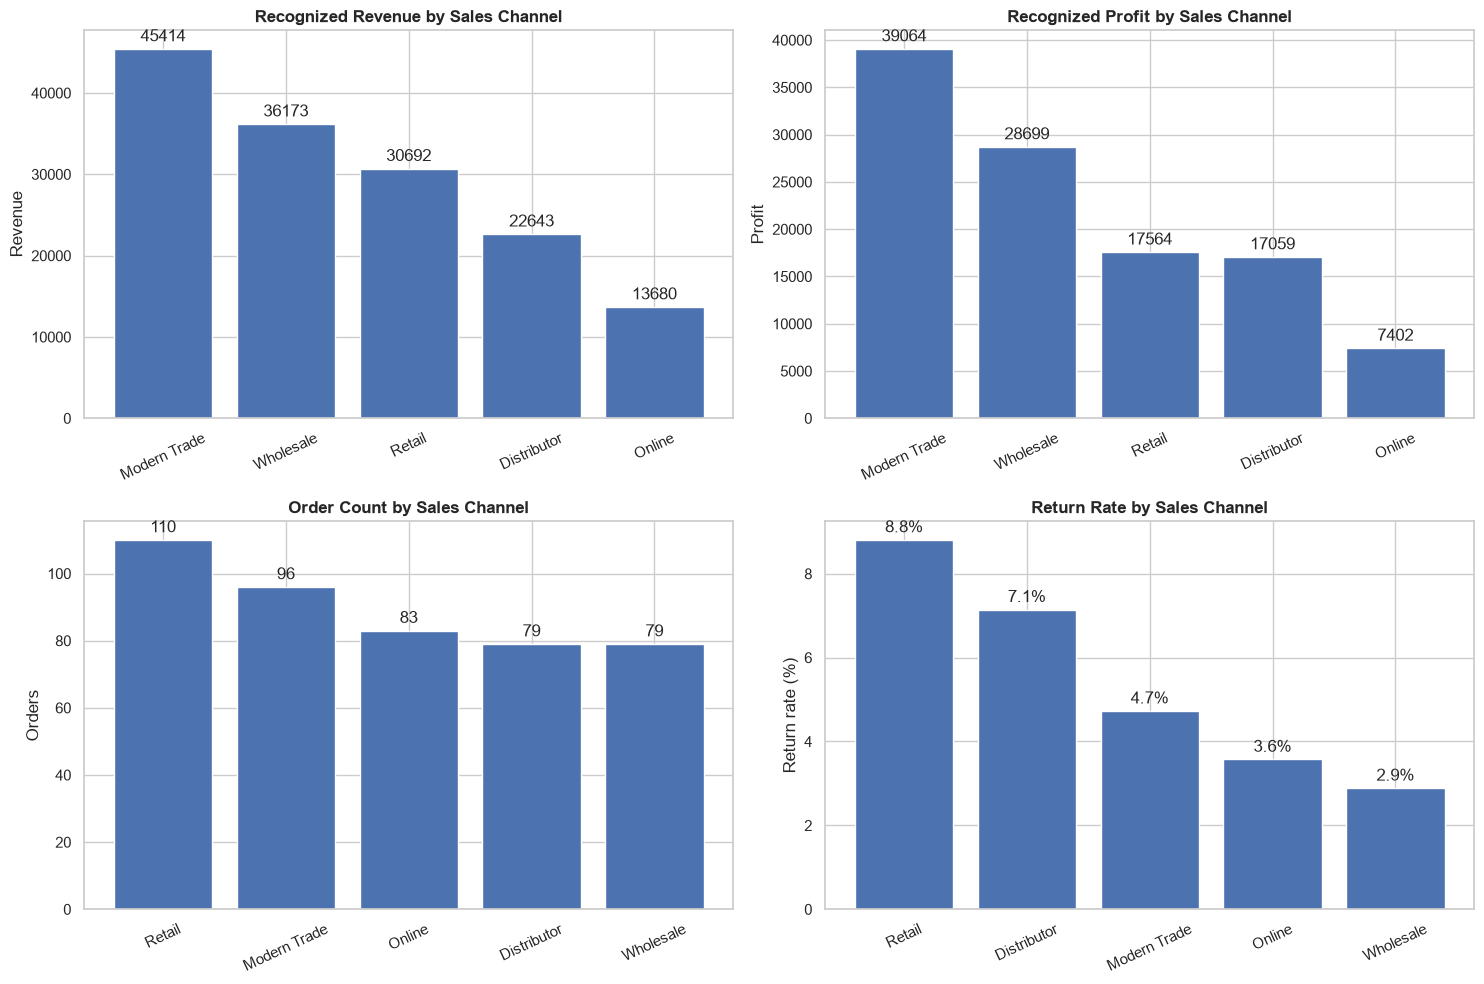

In [7]:
# 5.2 Channel performance charts
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

chart_items = [
    ("Revenue", "Recognized Revenue by Sales Channel", "Revenue", "%.0f"),
    ("Profit", "Recognized Profit by Sales Channel", "Profit", "%.0f"),
    ("Orders", "Order Count by Sales Channel", "Orders", "%.0f"),
    ("Return_Rate_%", "Return Rate by Sales Channel", "Return rate (%)", "%.1f%%")
]

for ax, (col, title, ylabel, label_fmt) in zip(axes.flat, chart_items):
    d = channel_perf.sort_values(col, ascending=False).copy()
    labels = d["Sales_Channel"].fillna("Unknown").astype(str)
    bars = ax.bar(labels, d[col])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)
    ax.bar_label(bars, fmt=label_fmt, padding=3)

plt.tight_layout()
plt.show()


In [8]:
# Pricing and Discount Analysis

In [9]:
# 6.1 Keep valid discount and quantity records.
pricing_data = recognized.loc[
    recognized["Discount_Pct"].between(0, 1) &
    recognized["Quantity"].gt(0) &
    ~recognized["Quantity_Amount_Mismatch_Flag"]
].copy()

pricing_data["Net_Selling_Price_Per_Unit"] = (
    pricing_data["Sales_Amount_Final"] / pricing_data["Quantity"]
)

total_pricing_units = pricing_data["Quantity"].sum()
weighted_selling_price = (
    pricing_data["Sales_Amount_Final"].sum() / total_pricing_units
    if total_pricing_units else np.nan
)

pricing_kpis = pd.DataFrame({
    "Metric": [
        "Average list unit price",
        "Weighted average net selling price per unit",
        "Average valid discount (%)",
        "Valid pricing records analyzed"
    ],
    "Value": [
        pricing_data["Unit_Price"].mean(),
        weighted_selling_price,
        pricing_data["Discount_Pct"].mean() * 100,
        len(pricing_data)
    ]
})

display(pricing_kpis.round(2))

# Group discounts into useful ranges.
discount_bins = [-0.000001, 0, 0.05, 0.10, 0.15, 1.000001]
discount_labels = ["No discount", ">0–5%", ">5–10%", ">10–15%", ">15%"]

pricing_data["Discount_Range"] = pd.cut(
    pricing_data["Discount_Pct"],
    bins=discount_bins,
    labels=discount_labels,
    include_lowest=True
)

discount_perf = (
    pricing_data.groupby("Discount_Range", observed=True)
    .agg(
        Revenue=("Recognized_Revenue", "sum"),
        Profit=("Recognized_Profit", "sum"),
        Units=("Recognized_Quantity", "sum"),
        Orders=("Order_ID", "nunique"),
        Average_Discount=("Discount_Pct", "mean")
    )
    .reset_index()
)

discount_perf["Profit_Margin_%"] = np.where(
    discount_perf["Revenue"] > 0,
    discount_perf["Profit"] / discount_perf["Revenue"] * 100,
    np.nan
)

display(discount_perf.round(2))


,Metric,Value
0,Average list unit price,1.70
1,Weighted average net selling price per unit,1.66
2,Average valid discount (%),4.75
3,Valid pricing records analyzed,399.00


,Discount_Range,Revenue,Profit,Units,Orders,Average_Discount,Profit_Margin_%
0,No discount,21085.15,5939.57,11386,127,0.00,28.17
1,>0–5%,15066.77,3979.55,9226,161,0.04,26.41
2,>5–10%,8206.11,2007.56,5731,64,0.10,24.46
3,>10–15%,4418.44,806.77,3108,43,0.15,18.26


In [10]:
# 6.2 Product-level discount comparison
product_discount = (
    pricing_data.groupby(["Product_ID", "Product_Name"], dropna=False)
    .agg(
        Average_Discount=("Discount_Pct", "mean"),
        Revenue=("Recognized_Revenue", "sum"),
        Profit=("Recognized_Profit", "sum"),
        Units=("Recognized_Quantity", "sum")
    )
    .reset_index()
)

product_discount["Average_Discount_%"] = product_discount["Average_Discount"] * 100
product_discount = product_discount.sort_values(
    "Average_Discount", ascending=False
)

display(product_discount[
    ["Product_ID", "Product_Name", "Average_Discount_%", "Revenue", "Profit", "Units"]
].head(10).round(2))


,Product_ID,Product_Name,Average_Discount_%,Revenue,Profit,Units
25,P999,Unknown Product,15.00,30.68,8.83,19
26,UNKNOWN,Toothpaste 150G,10.00,23.94,7.84,14
14,P012,Cheddar Cheese 200G,6.06,3145.29,698.09,1064
24,P022,Toothpaste 150G,5.95,2722.93,997.93,1500
7,P005,Choco Cream Biscuits,5.95,1302.6,413.46,1533
8,P006,Butter Cookies,5.71,1561.15,472.37,1111
4,P002,Orange Juice 1L,5.58,1740.73,384.48,1085
22,P020,Shampoo 340Ml,5.50,8718.08,2993.68,2602
18,P016,Popcorn 80G,5.44,986.89,365.39,1130
21,P019,Iodized Salt 1Kg,5.41,928.36,315.66,2785


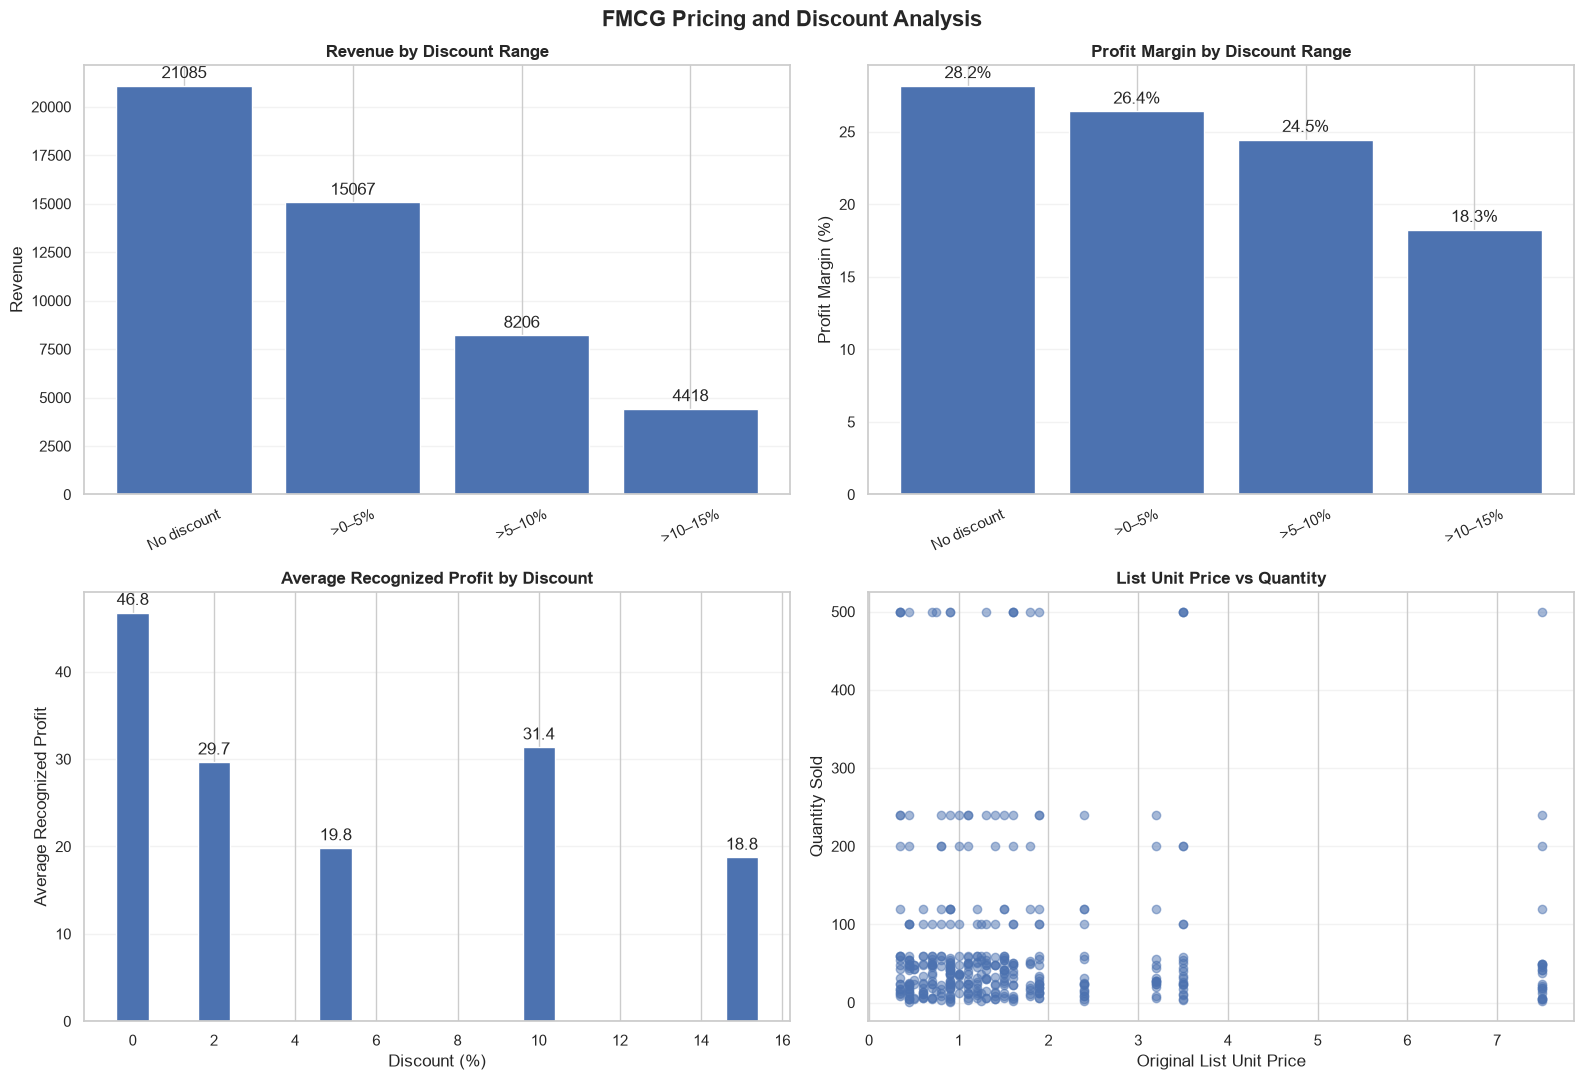

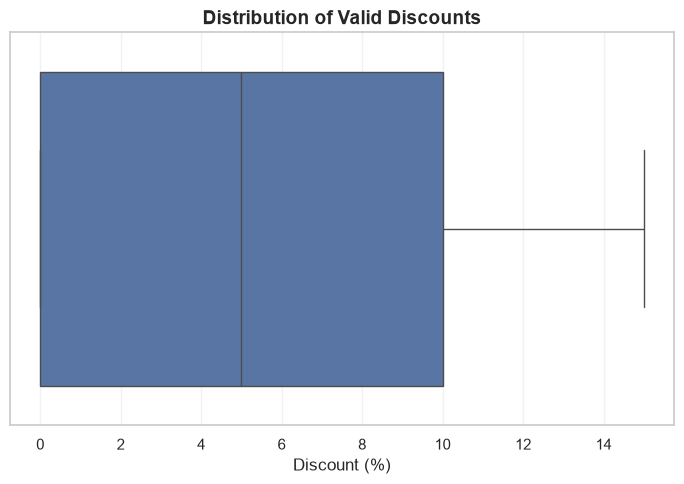

In [12]:

# 6.3 Pricing and Discount Analysis

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Prepare discount performance data
d = discount_perf.dropna(subset=["Discount_Range"]).copy()

# Calculate Profit Margin
d["Profit_Margin_%"] = (
    d["Profit"] / d["Revenue"].where(d["Revenue"] > 0) * 100
)

# 1. Revenue by Discount Range
bars = axes[0, 0].bar(
    d["Discount_Range"].astype(str),
    d["Revenue"]
)
axes[0, 0].set_title("Revenue by Discount Range")
axes[0, 0].set_ylabel("Revenue")
axes[0, 0].tick_params(axis="x", rotation=25)
axes[0, 0].bar_label(bars, fmt="%.0f", padding=3)


# 2. Profit Margin by Discount Range
bars = axes[0, 1].bar(
    d["Discount_Range"].astype(str),
    d["Profit_Margin_%"]
)
axes[0, 1].set_title("Profit Margin by Discount Range")
axes[0, 1].set_ylabel("Profit Margin (%)")
axes[0, 1].tick_params(axis="x", rotation=25)
axes[0, 1].axhline(0, color="black", linewidth=0.8)
axes[0, 1].bar_label(bars, fmt="%.1f%%", padding=3)


# 3. Average Recognized Profit by Discount
valid_profit = pricing_data.dropna(
    subset=["Discount_Pct", "Recognized_Profit"]
).copy()

avg_profit = (
    valid_profit.groupby("Discount_Pct")["Recognized_Profit"]
    .mean()
    .reset_index()
    .sort_values("Discount_Pct")
)

bars = axes[1, 0].bar(
    avg_profit["Discount_Pct"] * 100,
    avg_profit["Recognized_Profit"]
)
axes[1, 0].set_title("Average Recognized Profit by Discount")
axes[1, 0].set_xlabel("Discount (%)")
axes[1, 0].set_ylabel("Average Recognized Profit")
axes[1, 0].axhline(0, color="black", linewidth=0.8)
axes[1, 0].bar_label(bars, fmt="%.1f", padding=3)


# 4. Original Unit Price vs Quantity
# Use the original, unscaled price column here.
price_col = "Unit_Price"

price_data = pricing_data.copy()

price_data[price_col] = pd.to_numeric(
    price_data[price_col], errors="coerce"
)
price_data["Quantity"] = pd.to_numeric(
    price_data["Quantity"], errors="coerce"
)

price_data = price_data[
    (price_data[price_col] > 0) &
    (price_data["Quantity"] > 0)
].dropna(subset=[price_col, "Quantity"])

axes[1, 1].scatter(
    price_data[price_col],
    price_data["Quantity"],
    alpha=0.5
)
axes[1, 1].set_title("List Unit Price vs Quantity")
axes[1, 1].set_xlabel("Original List Unit Price")
axes[1, 1].set_ylabel("Quantity Sold")


# Improve overall presentation
for ax in axes.flat:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.suptitle("FMCG Pricing and Discount Analysis",
             fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()


# 5. Distribution of Valid Discounts
valid_discounts = pricing_data["Discount_Pct"].dropna() * 100

valid_discounts = valid_discounts[
    valid_discounts.between(0, 100)
]

plt.figure(figsize=(7, 5))

sns.boxplot(x=valid_discounts)

plt.title("Distribution of Valid Discounts",
          fontsize=14, fontweight="bold")
plt.xlabel("Discount (%)")
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


In [32]:
pricing_data.columns.tolist()

['Order_ID',
 'Order_Date',
 'Customer_ID',
 'Region',
 'City',
 'Product_ID',
 'Product_Name',
 'Category',
 'Brand',
 'Quantity',
 'Unit_Price',
 'Discount_Pct',
 'Sales_Channel',
 'Payment_Method',
 'Returned',
 'Order_Status',
 'Sales_Amount',
 'Cost_Amount',
 'Profit',
 'Discount_Invalid_Flag',
 'Returned_Binary',
 'Quantity_Invalid_Flag',
 'Unit_Price_Invalid_Flag',
 'Order_Date_Invalid_Flag',
 'Product_Name_Master',
 'Category_Master',
 'Brand_Master',
 'Unit_Cost',
 'Customer_Type',
 'Loyalty_Tier',
 'Join_Date',
 'Sales_Amount_Calc',
 'Cost_Amount_Calc',
 'Quantity_Amount_Mismatch_Flag',
 'Sales_Amount_Final',
 'Cost_Amount_Final',
 'Profit_Final',
 'Is_Returned',
 'Is_Cancelled',
 'Is_Delivered',
 'Is_Recognized',
 'Recognized_Revenue',
 'Recognized_Cost',
 'Recognized_Profit',
 'Recognized_Quantity',
 'Net_Selling_Price_Per_Unit',
 'Discount_Range']

In [33]:
price_col = "List_Unit_Price"

In [34]:
price_col = "Unit_Price"

In [13]:
pricing_data[price_col].describe()

count       393.0
mean     1.701781
std       1.69707
min          -2.5
25%           0.7
50%           1.2
75%           1.9
max           7.5
Name: Unit_Price, dtype: Float64

In [14]:
fact[["Discount_Pct", "Recognized_Profit"]].describe()

,Discount_Pct,Recognized_Profit
count,567.000000,605.0
mean,0.048272,181.466194
std,0.048815,1928.822547
min,0.000000,-212.0
25%,0.000000,0.0
50%,0.050000,6.384
75%,0.100000,18.8
max,0.150000,36624.0


In [15]:
fact[["Unit_Price", "Quantity"]].describe()

,Unit_Price,Quantity
count,599.0,573.0
mean,1.664858,144.766143
std,1.702238,785.85278
min,-2.5,-500.0
25%,0.7,17.0
50%,1.2,36.0
75%,1.9,59.0
max,7.5,9999.0


In [16]:
fact.loc[fact["Unit_Price"] < 0,
         ["Unit_Price", "Quantity"]]

,Unit_Price,Quantity
77,-2.5,56
304,-2.5,<NA>
334,-2.5,24
370,-2.5,2
440,-2.5,100


In [20]:
pricing_data["Discount_Pct"].describe()

count    399.000000
mean       0.047469
std        0.049361
min        0.000000
25%        0.000000
50%        0.050000
75%        0.100000
max        0.150000
Name: Discount_Pct, dtype: float64

In [21]:
sorted(pricing_data["Discount_Pct"].dropna().unique())

[np.float64(0.0),
 np.float64(0.02),
 np.float64(0.05),
 np.float64(0.1),
 np.float64(0.15)]

In [22]:
pricing_data.loc[
    pricing_data["Discount_Pct"] < 0,
    ["Discount_Pct", "Recognized_Profit"]
]

,Discount_Pct,Recognized_Profit


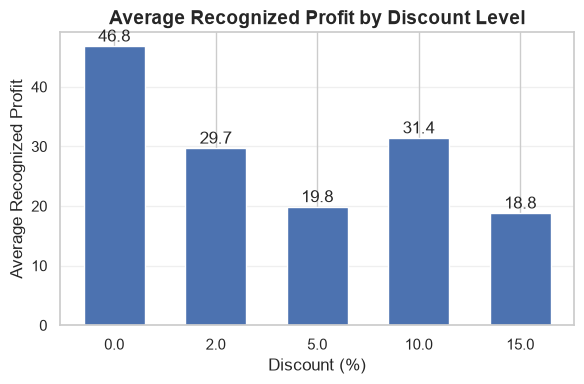

In [29]:

# Average Recognized Profit by Valid Discount

# 1. Prepare data
profit_data = pricing_data[
    ["Discount_Pct", "Recognized_Profit"]
].copy()

profit_data["Discount_Pct"] = pd.to_numeric(
    profit_data["Discount_Pct"], errors="coerce"
)

profit_data["Recognized_Profit"] = pd.to_numeric(
    profit_data["Recognized_Profit"], errors="coerce"
)

# 2. Keep valid discount values
profit_data = profit_data.dropna()

profit_data = profit_data[
    profit_data["Discount_Pct"].between(0, 1)
]

# 3. Calculate average profit for each discount
avg_profit = (
    profit_data.groupby("Discount_Pct")["Recognized_Profit"]
    .mean()
    .reset_index()
    .sort_values("Discount_Pct")
)

# 4. Convert discount into percentage
avg_profit["Discount_%"] = avg_profit["Discount_Pct"] * 100

# 5. Create visualization
plt.figure(figsize=(6, 4))

bars = plt.bar(
    avg_profit["Discount_%"].astype(str),
    avg_profit["Recognized_Profit"],
    width=0.6
)

plt.bar_label(bars, fmt="%.1f", padding=1)

plt.title("Average Recognized Profit by Discount Level",
          fontsize=14, fontweight="bold")

plt.xlabel("Discount (%)")
plt.ylabel("Average Recognized Profit")

plt.grid(axis="y", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()


In [25]:
# Profitability Analysis

In [26]:
# 7.1 Overall profitability KPIs
total_recognized_revenue = recognized["Recognized_Revenue"].sum()
total_recognized_cost = recognized["Recognized_Cost"].sum()
total_recognized_profit = recognized["Recognized_Profit"].sum()

missing_cost_rows = recognized["Recognized_Cost"].isna().sum()
profit_fallback_rows = (
    recognized["Cost_Amount_Final"].isna() &
    recognized["Profit"].notna()
).sum()

profitability_kpis = pd.DataFrame({
    "KPI": [
        "Recognized Revenue",
        "Recognized Cost (available values)",
        "Recognized Profit (calculated / source fallback)",
        "Profit Margin (%) — provisional",
        "Recognized rows with missing cost",
        "Rows using source Profit because cost is missing",
        "Revenue less available cost"
    ],
    "Value": [
        total_recognized_revenue,
        total_recognized_cost,
        total_recognized_profit,
        total_recognized_profit / total_recognized_revenue * 100
            if total_recognized_revenue else np.nan,
        missing_cost_rows,
        profit_fallback_rows,
        total_recognized_revenue - total_recognized_cost
    ]
})

display(profitability_kpis.round(2))

print(
    "Financial caution: cost is missing on some recognized rows. "
    "The overall profit margin is provisional and should be reconciled "
    "before being treated as a final financial result."
)


,KPI,Value
0,Recognized Revenue,148602.25
1,Recognized Cost (available values),38074.76
2,Recognized Profit (calculated / source fallback),109787.05
3,Profit Margin (%) — provisional,73.88
4,Recognized rows with missing cost,9.00
5,Rows using source Profit because cost is missing,9.00
6,Revenue less available cost,110527.49


Financial caution: cost is missing on some recognized rows. The overall profit margin is provisional and should be reconciled before being treated as a final financial result.


In [27]:
# 7.2 Profitability by business dimensions
def profitability_by(df, column):
    result = (
        df.groupby(column, dropna=False)
        .agg(
            Revenue=("Recognized_Revenue", "sum"),
            Cost=("Recognized_Cost", "sum"),
            Profit=("Recognized_Profit", "sum"),
            Orders=("Order_ID", "nunique")
        )
        .reset_index()
    )

    result["Profit_Margin_%"] = np.where(
        result["Revenue"] > 0,
        result["Profit"] / result["Revenue"] * 100,
        np.nan
    )
    return result.sort_values("Profit", ascending=False)

category_profit = profitability_by(recognized, "Category")
brand_profit = profitability_by(recognized, "Brand")
region_profit = profitability_by(recognized, "Region")
channel_profit = profitability_by(recognized, "Sales_Channel")

product_profit = (
    recognized.groupby(
        ["Product_ID", "Product_Name", "Category", "Brand"],
        dropna=False
    )
    .agg(
        Revenue=("Recognized_Revenue", "sum"),
        Cost=("Recognized_Cost", "sum"),
        Profit=("Recognized_Profit", "sum"),
        Units=("Recognized_Quantity", "sum"),
        Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

product_profit["Profit_Margin_%"] = np.where(
    product_profit["Revenue"] > 0,
    product_profit["Profit"] / product_profit["Revenue"] * 100,
    np.nan
)
product_profit = product_profit.sort_values("Profit", ascending=False)

print("Profit by category")
display(category_profit.round(2))

print("Profit by brand")
display(brand_profit.round(2))

print("Profit by region")
display(region_profit.round(2))

print("Profit by sales channel")
display(channel_profit.round(2))

print("Top 10 profitable products")
display(product_profit.head(10).round(2))

loss_products = product_profit.loc[product_profit["Profit"] < 0].sort_values("Profit")
print("Loss-making products")
display(loss_products.round(2))


Profit by category


,Category,Revenue,Cost,Profit,Orders,Profit_Margin_%
2,Cooking Essentials,51477.84,12551.84,38878.0,66,75.52
6,Snacks,34732.42,4250.92,30481.5,57,87.76
5,Personal Care,37301.98,8547.3,28713.28,77,76.98
1,Biscuits,10200.92,3059.7,7064.12,67,69.25
3,Dairy,8344.72,5366.5,2912.22,56,34.90
0,Beverages,3920.04,2698.6,1195.5,66,30.50
4,Noodles,2624.34,1599.9,542.44,58,20.67


Profit by brand


,Brand,Revenue,Cost,Profit,Orders,Profit_Margin_%
8,Goldharvest,50373.99,11826.5,38499.49,43,76.43
10,Nuthouse,32715.02,2968.35,29746.67,23,90.93
2,Brightsmile,27173.03,1941.2,25190.43,28,92.70
4,Crunchtime,7209.99,2125.9,5006.99,50,69.45
14,Silkycare,9682.07,6330.1,3351.97,48,34.62
11,Purefarm,6904.49,4412.8,2491.69,37,36.09
7,Goldenoat,2990.93,933.8,2057.13,17,68.78
3,Crispybite,1986.71,1260.72,725.99,33,36.54
6,Freshfizz,2719.4,2016.35,703.05,32,25.85
5,Dairyjoy,1440.22,953.7,420.52,19,29.20


Profit by region


,Region,Revenue,Cost,Profit,Orders,Profit_Margin_%
3,West,50223.65,8341.83,41827.82,111,83.28
0,East,33580.95,3547.55,29992.0,77,89.31
2,South,39956.97,11284.37,28086.76,118,70.29
1,North,24840.68,14901.01,9880.47,140,39.78


... (2 outputs left out)

Top 10 profitable products


,Product_ID,Product_Name,Category,Brand,Revenue,Cost,Profit,Units,Orders,Profit_Margin_%
20,P018,Basmati Rice 5Kg,Cooking Essentials,Goldharvest,48261.23,10048.5,38212.72,1575,25,79.18
17,P015,Salted Peanuts 200G,Snacks,Nuthouse,32715.02,2968.35,29746.67,2509,23,90.93
24,P022,Toothpaste 150G,Personal Care,Brightsmile,27173.03,1941.2,25190.43,1585,28,92.70
7,P005,Choco Cream Biscuits,Biscuits,Crunchtime,5481.21,945.98,4483.61,1596,26,81.80
22,P020,Shampoo 340Ml,Personal Care,Silkycare,8765.68,5759.6,3006.08,2618,25,34.29
9,P007,Digestive Biscuits,Biscuits,Goldenoat,2990.93,933.8,2057.13,984,17,68.78
13,P011,Full Cream Milk 1L,Dairy,Purefarm,3699.92,1915.2,1784.72,1801,18,48.24
14,P012,Cheddar Cheese 200G,Dairy,Purefarm,3145.29,2447.2,698.09,1064,18,22.19
8,P006,Butter Cookies,Biscuits,Crunchtime,1674.63,1142.68,506.47,1166,23,30.24
4,P002,Orange Juice 1L,Beverages,Freshfizz,1927.93,1486.25,441.68,1189,14,22.91


Loss-making products


,Product_ID,Product_Name,Category,Brand,Revenue,Cost,Profit,Units,Orders,Profit_Margin_%


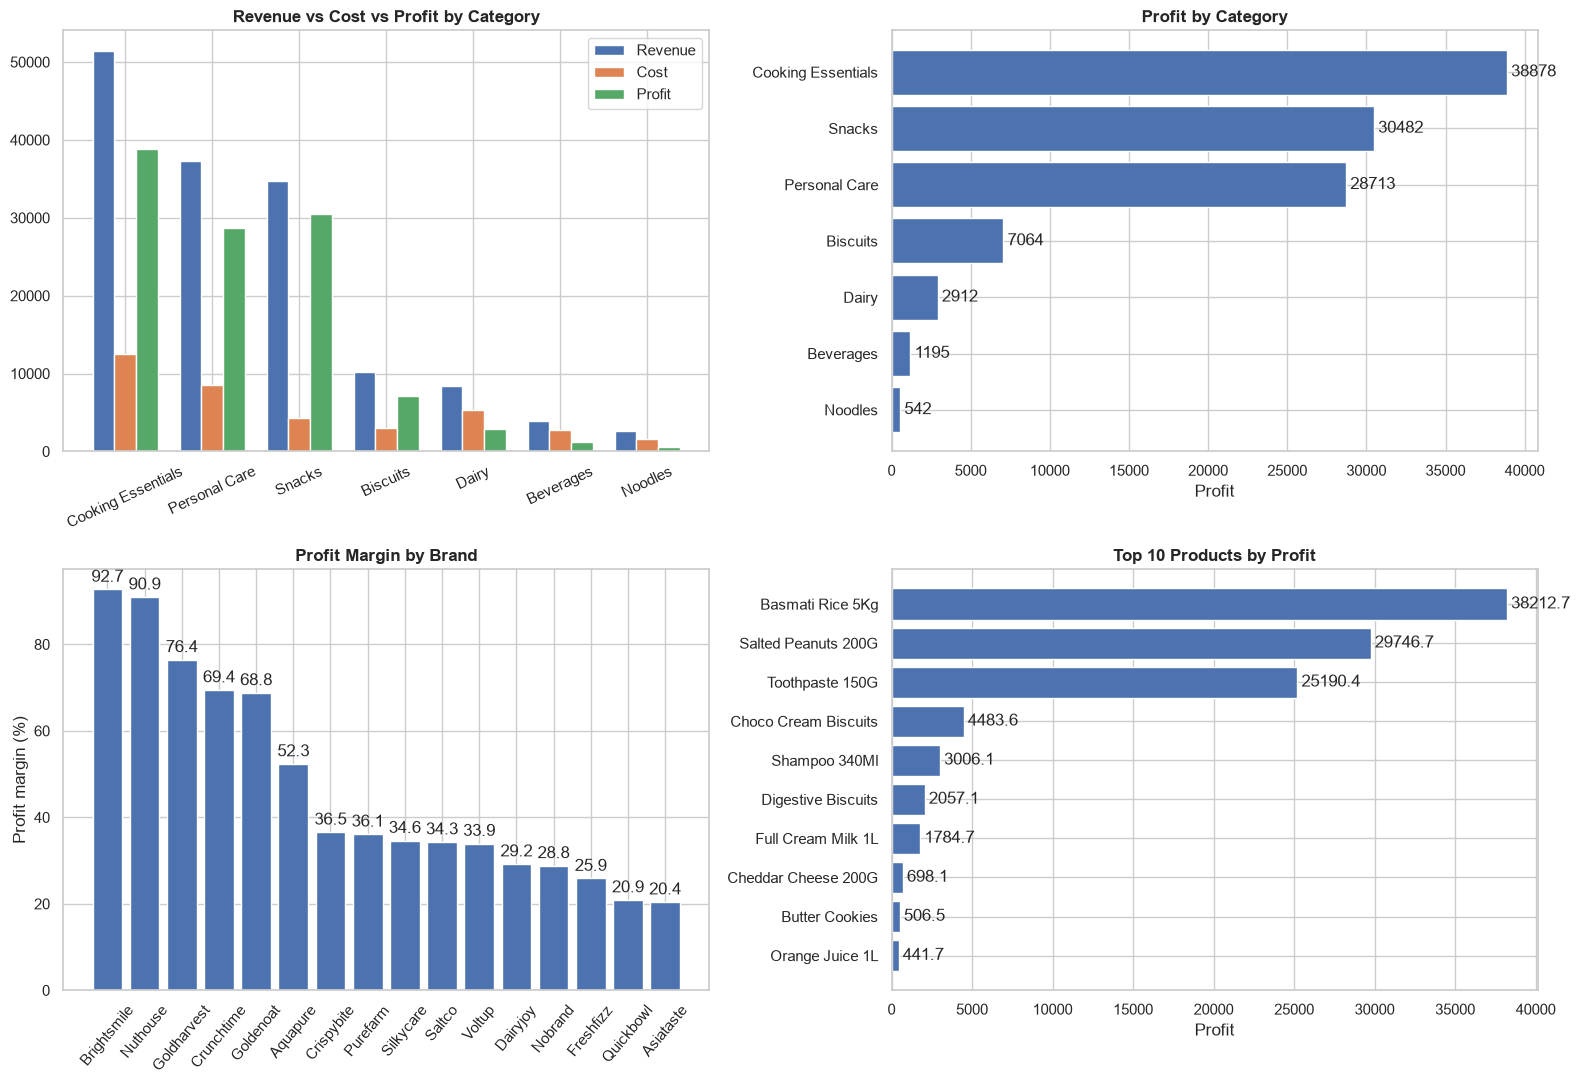

In [34]:
# 7.3 Profitability charts
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Revenue, cost and profit by category.
d = category_profit.sort_values("Revenue", ascending=False)
x = np.arange(len(d))
width = 0.25

axes[0, 0].bar(x - width, d["Revenue"], width, label="Revenue")
axes[0, 0].bar(x, d["Cost"], width, label="Cost")
axes[0, 0].bar(x + width, d["Profit"], width, label="Profit")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(d["Category"].fillna("Unknown").astype(str), rotation=25)
axes[0, 0].set_title("Revenue vs Cost vs Profit by Category")
axes[0, 0].legend()

# Profit by category.
d = category_profit.sort_values("Profit", ascending=True)
bars = axes[0, 1].barh(d["Category"].fillna("Unknown").astype(str), d["Profit"])
axes[0, 1].set_title("Profit by Category")
axes[0, 1].set_xlabel("Profit")
axes[0, 1].bar_label(bars, fmt="%.0f", padding=3)

# Profit margin by brand.
d = brand_profit.sort_values("Profit_Margin_%", ascending=False)
bars = axes[1, 0].bar(
    d["Brand"].fillna("Unknown").astype(str),
    d["Profit_Margin_%"]
)
axes[1, 0].set_title("Profit Margin by Brand")
axes[1, 0].set_ylabel("Profit margin (%)")
axes[1, 0].tick_params(axis="x", rotation=50)
axes[1, 0].bar_label(bars, fmt="%.1f", padding=3)

# Top 10 profitable products.
d = product_profit.head(10).sort_values("Profit", ascending=True)
bars = axes[1, 1].barh(
    d["Product_Name"].fillna("Unknown").astype(str),
    d["Profit"]
)
axes[1, 1].set_title("Top 10 Products by Profit")
axes[1, 1].set_xlabel("Profit")
axes[1, 1].bar_label(bars, fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()


In [35]:
OUTPUT_FILE = "FMCG_EDA_5_to_7_Results_Standalone.xlsx"

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    channel_perf.to_excel(writer, sheet_name="Channel_Performance", index=False)
    pricing_kpis.to_excel(writer, sheet_name="Pricing_KPIs", index=False)
    discount_perf.to_excel(writer, sheet_name="Discount_Performance", index=False)
    product_discount.to_excel(writer, sheet_name="Product_Discounts", index=False)
    profitability_kpis.to_excel(writer, sheet_name="Profitability_KPIs", index=False)
    category_profit.to_excel(writer, sheet_name="Category_Profit", index=False)
    brand_profit.to_excel(writer, sheet_name="Brand_Profit", index=False)
    region_profit.to_excel(writer, sheet_name="Region_Profit", index=False)
    channel_profit.to_excel(writer, sheet_name="Channel_Profit", index=False)
    product_profit.to_excel(writer, sheet_name="Product_Profit", index=False)
    loss_products.to_excel(writer, sheet_name="Loss_Making_Products", index=False)

print("Excel export completed:", OUTPUT_FILE)


Excel export completed: FMCG_EDA_5_to_7_Results_Standalone.xlsx
